# Tugas 2 — Deteksi Transaksi *Fraud* (Klasifikasi Biner)

Notebook ini mengerjakan Tugas 2 langkah demi langkah. Setiap butir memanggil fungsi di
`kode/src/klasifikasi/` (urutannya sama dengan `python kode/run_all.py --stages klasifikasi`),
menampilkan hasil yang dikembalikan fungsi tersebut, lalu menyimpan JSON hasil ke `kode/results/` dan
grafik ke `kode/figures/`. Butir 2a dipecah per pemeriksaan; butir 2b–2g memanggil fungsi utama
modulnya, yang di dalamnya memuat data, membangun fitur, dan menjalankan *fold* validasi.

| Butir | Isi | Modul | Penanggung jawab |
| --- | --- | --- | --- |
| 2a | Audit label dan fitur serta pengukuran dampaknya | `audit.py`, `audit_dampak.py` | Firdaus Arif Ramadhani |
| 2b | Validasi berbasis waktu yang tahan *right-censoring* | `validation.py` | Firdaus Arif Ramadhani |
| 2c | Fitur perilaku kausal pengguna dan *merchant* | `features.py` | Rainaldi Pakpahan |
| 2d | Penanganan *class imbalance* dan perbandingan model | `models.py` | Rainaldi Pakpahan |
| 2e | Pergeseran pola *fraud* dan adaptasi model | `shift.py` | Rainaldi Pakpahan |
| 2f | Kalibrasi probabilitas dan aturan keputusan berbasis biaya | `calibration.py` | Rainaldi Pakpahan |
| 2g | Analisis *error*, SHAP, dan `prediksi_klasifikasi.csv` | `analysis.py` | Rainaldi Pakpahan |

Metrik penilaian: PR-AUC dari `prob` dan biaya total = jumlah nominal *fraud* yang lolos + Rp25.000 ×
jumlah transaksi yang ditandai. Seluruh langkah memakai `SEED = 42`.

## Persiapan

Sel ini menyiapkan *path*, *seed* global, dan pembantu tampilan: `ringkas()` untuk mencetak kamus hasil
fungsi, `tabel_metrik()` untuk mengubahnya menjadi tabel, dan `tampilkan_gambar()` untuk grafik. Data dibaca dari folder `data/` di *root* repositori
(atau dari variabel lingkungan `UTS_ML_DATA_DIR`).

In [1]:
import json
import sys
import warnings
from io import BytesIO
from pathlib import Path

import matplotlib

# Peringatan informatif yang tidak memengaruhi hasil (deprecation pandas, tqdm, format keluaran SHAP)
warnings.filterwarnings("ignore", message="Constructing a Categorical with a dtype")
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")

# Backend non-interaktif: grafik disimpan ke kode/figures/ lalu ditampilkan dari berkasnya
matplotlib.use("Agg")

import pandas as pd  # noqa: E402
from IPython.display import Image, Markdown, display  # noqa: E402
from PIL import Image as PILImage  # noqa: E402

# Notebook dijalankan dari kode/notebooks/; folder kode/ dimasukkan ke sys.path
KODE_DIR = Path.cwd().resolve()
if KODE_DIR.name == "notebooks":
    KODE_DIR = KODE_DIR.parent
if str(KODE_DIR) not in sys.path:
    sys.path.insert(0, str(KODE_DIR))

from src.config import FIGURES_DIR, REPO_ROOT, RESULTS_DIR, SEED  # noqa: E402
from src.utils import set_global_seed  # noqa: E402

set_global_seed(SEED)
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)


def baca_hasil(nama: str) -> dict:
    """Baca berkas JSON hasil eksperimen dari kode/results/."""
    return json.loads((RESULTS_DIR / nama).read_text(encoding="utf-8"))


def tampilkan_gambar(nama, lebar: int = 1100) -> None:
    """Tampilkan grafik dari kode/figures/ (diperkecil agar notebook tetap ringan)."""
    jalur = Path(nama)
    gambar = PILImage.open(jalur if jalur.is_absolute() else FIGURES_DIR / jalur)
    if gambar.width > lebar:
        tinggi = round(gambar.height * lebar / gambar.width)
        gambar = gambar.resize((lebar, tinggi), PILImage.LANCZOS)
    buffer = BytesIO()
    gambar.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


def ringkas(obj, maks_baris: int = 25) -> None:
    """Cetak hasil fungsi (kamus/daftar) sebagai JSON berindentasi, dipotong bila panjang."""
    baris = json.dumps(obj, indent=1, ensure_ascii=False, default=str).splitlines()
    print("\n".join(baris[:maks_baris]))
    if len(baris) > maks_baris:
        print(f"... ({len(baris) - maks_baris} baris lagi)")


def tabel_metrik(kamus: dict, kolom: list[str] | None = None) -> pd.DataFrame:
    """Ubah {nama: {metrik: nilai}} menjadi tabel (baris = nama, kolom = metrik)."""
    df = pd.DataFrame.from_dict(kamus, orient="index")
    return df[kolom] if kolom else df


print(f"Folder kode : {KODE_DIR.relative_to(REPO_ROOT)}/")
print(f"Seed global : {SEED}")

Folder kode : kode/
Seed global : 42


## 2a. Audit Label dan Fitur

*Penanggung jawab: Firdaus Arif Ramadhani*

Pemeriksaan yang dijalankan `audit.py`:

- **Skema, waktu, dan ID:** dimensi, duplikat, irisan *train*–*test*, urutan baris, keacakan ID.
- **Jeda label (*right-censoring*):** *fraud* baru terkonfirmasi beberapa hari setelah transaksi,
  sehingga label Agustus 2025 belum lengkap pada tanggal penarikan data.
- ***Leakage*:** `flag_review_manual` terjadi sesudah transaksi sehingga tidak boleh dipakai.
- **Kualitas data:** *missing* terstruktur, `umur_merchant_hari < 0`, `persen_saldo` yang terpotong di 50,
  entitas *unseen*.
- ***Screening* `v01`–`v50`:** memisahkan fitur anonim yang bersinyal dari yang *noise*.
- **Pergeseran pola:** gelombang *fraud* QRIS mulai Agustus 2025.
- **Dampak:** empat eksperimen mengukur efek setiap temuan pada split kronologis yang labelnya matang.

In [2]:
from src.config import KLASIFIKASI_TEST_PATH, KLASIFIKASI_TRAIN_PATH
from src.klasifikasi.audit import (
    cek_keacakan_id,
    cek_kualitas_fitur_dan_anomali,
    cek_label_dan_delay_konfirmasi,
    cek_leakage_review_manual,
    cek_pergeseran_pola_fraud,
    cek_rentang_waktu_dan_urutan,
    cek_screening_fitur_v,
    cek_skema_dan_duplikat,
)
from src.klasifikasi.audit_dampak import jalankan_semua_dampak
from src.klasifikasi.preprocess import muat_data_klasifikasi
from src.utils import save_json

train, test = muat_data_klasifikasi(KLASIFIKASI_TRAIN_PATH, KLASIFIKASI_TEST_PATH)
print(f"train: {train.shape[0]:,} transaksi x {train.shape[1]} kolom")
print(f"test : {test.shape[0]:,} transaksi x {test.shape[1]} kolom")
audit = {}

train: 403,077 transaksi x 86 kolom
test : 106,674 transaksi x 85 kolom


**2a.1–2a.3 Skema, waktu, dan keacakan ID** — `cek_skema_dan_duplikat()`, `cek_rentang_waktu_dan_urutan()`,
`cek_keacakan_id()`

In [3]:
audit["skema"] = cek_skema_dan_duplikat(train, test)
audit["waktu"] = cek_rentang_waktu_dan_urutan(train, test)
audit["id"] = cek_keacakan_id(train)
ringkas({k: audit[k] for k in ("skema", "waktu", "id")}, maks_baris=40)

{
 "skema": {
  "train_shape": [
   403077,
   85
  ],
  "test_shape": [
   106674,
   84
  ],
  "train_only_cols": [
   "is_fraud"
  ],
  "test_only_cols": [],
  "dup_id_train": 0,
  "dup_id_test": 0,
  "dup_rows_train": 0,
  "dup_rows_test": 0,
  "overlap_id_train_test": 0
 },
 "waktu": {
  "train_min": "2025-01-01 00:02:53",
  "train_max": "2025-08-31 23:58:04",
  "test_min": "2025-09-01 00:01:51",
  "test_max": "2025-10-31 23:57:22",
  "train_terurut_waktu": false,
  "test_terurut_waktu": false,
  "volume_bulanan_train": {
   "2025-01": 50432,
   "2025-02": 46240,
   "2025-03": 51048,
   "2025-04": 47413,
   "2025-05": 52331,
   "2025-06": 50375,
   "2025-07": 52334,
   "2025-08": 52904
  },
  "volume_bulanan_test": {
   "2025-09": 52384,
   "2025-10": 54290
... (10 baris lagi)


**2a.4 Jeda konfirmasi label** — `cek_label_dan_delay_konfirmasi()`

,laju_fraud_pct
Seluruh train,0.6505
Jan–Jul (label matang),0.6788
Agustus (tersensor),0.4631


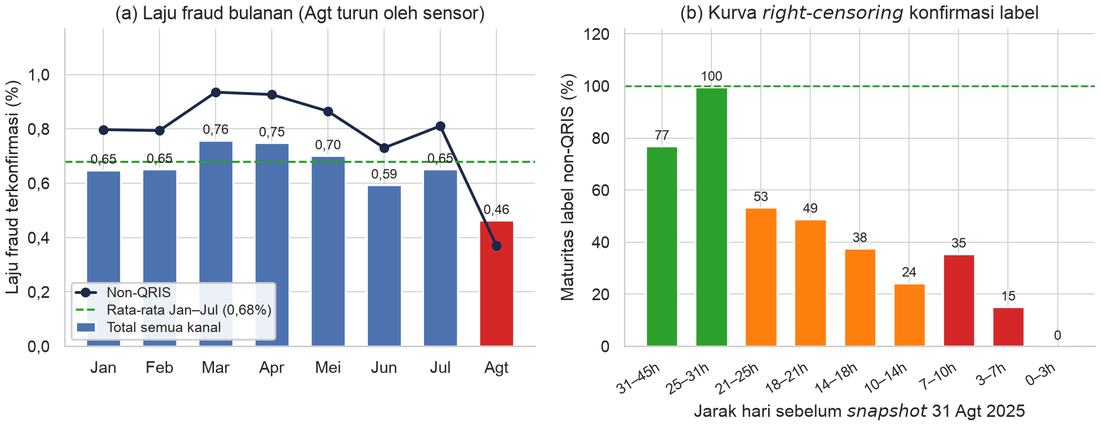

In [4]:
audit["label_delay"] = cek_label_dan_delay_konfirmasi(train, simpan_plot=True)
label = audit["label_delay"]
display(pd.Series({
    "Seluruh train": label["laju_fraud_total_pct"],
    "Jan–Jul (label matang)": label["laju_fraud_matang_pct"],
    "Agustus (tersensor)": label["laju_fraud_agustus_pct"],
}, name="laju_fraud_pct").to_frame())
tampilkan_gambar("task2_2a1_label_delay.png")

**2a.5 *Leakage* `flag_review_manual`** — `cek_leakage_review_manual()`

{
 "kontingensi_train": {
  "rev0_nonfraud": 395652,
  "rev0_fraud": 527,
  "rev1_nonfraud": 4803,
  "rev1_fraud": 2095
 },
 "proporsi_fraud_yang_direview_pct": 79.90083905415713,
 "precision_review_di_train_pct": 30.371122064366485,
 "laju_review_train_total_pct": 1.7113355512718413,
 "laju_review_train_nonfraud_pct": 1.1993856987676517,
 "laju_review_test_total_pct": 1.2299154433132722,
 "roc_auc_univariat_matang": 0.8941280619711343,
 "pr_auc_univariat_matang": 0.2531215786272709,
 "laju_review_bulanan_pct": {
  "2025-01": 1.681472081218274,
  "2025-02": 1.7560553633217992,
  "2025-03": 1.7806770098730607,
  "2025-04": 1.8876679391728008,
  "2025-05": 1.6414744606447422,
  "2025-06": 1.6853598014888338,
  "2025-07": 1.6681316161577557,
  "2025-08": 1.6123544533494631,
  "2025-09": 1.2809254734270006,
  "2025-10": 1.1806962608215141
... (53 baris lagi)


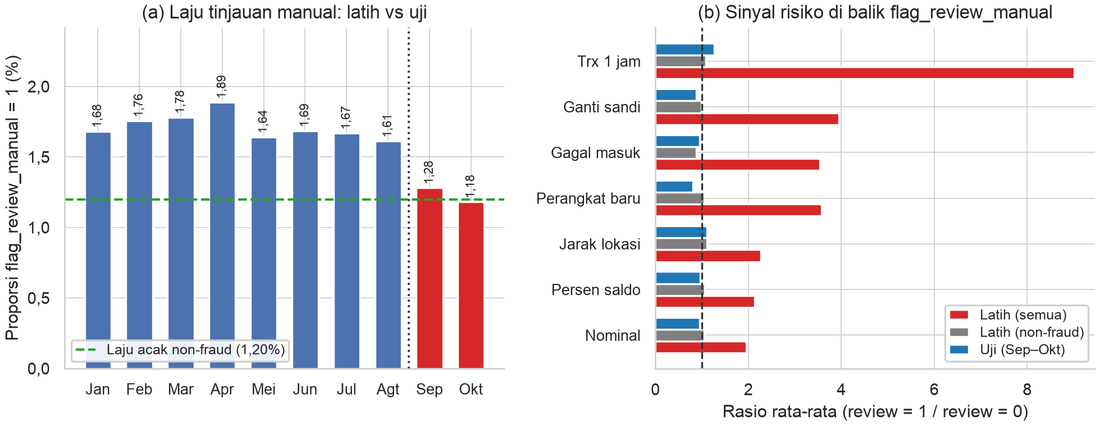

In [5]:
audit["leakage_review"] = cek_leakage_review_manual(train, test, simpan_plot=True)
ringkas(audit["leakage_review"])
tampilkan_gambar("task2_2a2_leakage_review.png")

**2a.6 Kualitas fitur** — `cek_kualitas_fitur_dan_anomali()`

In [6]:
audit["kualitas"] = cek_kualitas_fitur_dan_anomali(train, test)
ringkas(audit["kualitas"])

{
 "missing": {
  "menit_sejak_trx_terakhir": {
   "train_na_pct": 25.459403538281766,
   "test_na_pct": 10.741136546862403
  },
  "rasio_nominal_rata2": {
   "train_na_pct": 25.459403538281766,
   "test_na_pct": 10.741136546862403
  }
 },
 "kecocokan_missing_dengan_trx_pertama": 1.0,
 "laju_fraud_trx_pertama_matang_pct": 0.9369870982486029,
 "laju_fraud_trx_berulang_matang_pct": 0.5809213609707492,
 "umur_merchant_negatif": {
  "train_count": 955,
  "train_pct": 0.23692743570087105,
  "train_min_hari": -274.0,
  "train_fraud_rate_pct": 20.31413612565445,
  "matang_fraud_rate_pct": 20.17259978425027,
  "test_count": 20,
  "test_pct": 0.018748711026116954
 },
 "persen_saldo_capped_50": {
  "train_count": 215,
... (188 baris lagi)


**2a.7 *Screening* `v01`–`v50`** — `cek_screening_fitur_v()`

Fitur v bersinyal: ['v03', 'v11', 'v19', 'v26', 'v29', 'v38', 'v42', 'v47']
{
 "kolom": "v15",
 "status": "drift_noise",
 "auc_matang": 0.5032570350465311,
 "kekuatan_sinyal_matang": 0.003257035046531076,
 "auc_agustus": 0.47052239456712436,
 "kekuatan_sinyal_agustus": 0.029477605432875642,
 "ks_train_test": 0.5018644064364115,
 "spearman_waktu_train": 0.5778969484809683
}


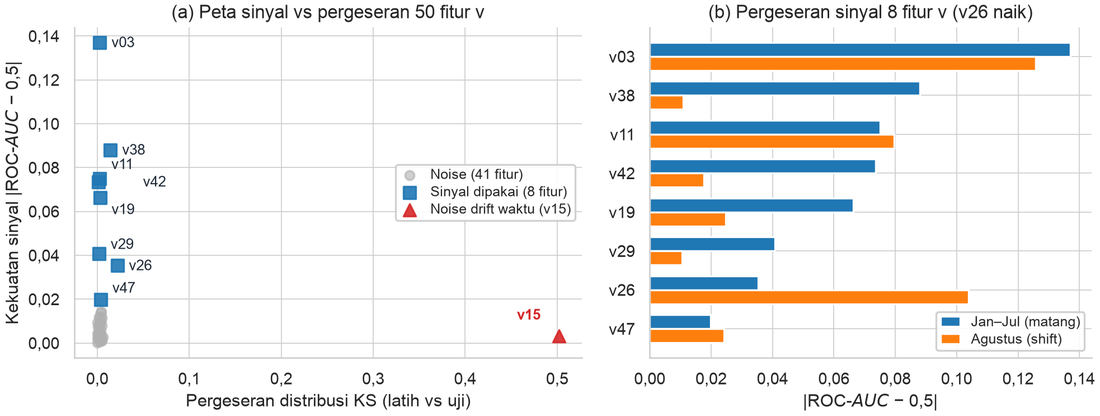

In [7]:
audit["v_screening"] = cek_screening_fitur_v(train, test, simpan_plot=True)
print("Fitur v bersinyal:", audit["v_screening"]["signal_v_cols"])
ringkas(audit["v_screening"]["v15_detail"])
tampilkan_gambar("task2_2a3_v_screening.png")

**2a.8 Pergeseran pola *fraud*** — `cek_pergeseran_pola_fraud()`

{
 "laju_qris_jan_jul_pct": 0.11924203540970009,
 "laju_qris_agustus_pct": 0.7887517146776405,
 "laju_jasa_lainnya_jan_jul_pct": 0.1008500216107189,
 "laju_jasa_lainnya_agustus_pct": 3.1201248049921997,
 "persen_bulat100k_pada_fraud_qris_agt": 79.34782608695652,
 "persen_bulat100k_pada_normal_jan_jul": 0.07360636695074124,
 "laju_fraud_qris_bulat100k_agt_awal_1_10_pct": 86.36363636363636,
 "n_qris_bulat100k_test_sep_okt": 461,
 "laju_kanal_bulanan_pct": {
  "aplikasi": {
   "2025-01": 0.40812705172566766,
   "2025-02": 0.339459774016779,
   "2025-03": 0.4405674508767292,
   "2025-04": 0.5082352941176471,
   "2025-05": 0.3936165661233047,
   "2025-06": 0.30668029690208454,
   "2025-07": 0.3395512765408751,
   "2025-08": 0.134850400337126
  },
  "kartu": {
   "2025-01": 1.8461538461538463,
   "2025-02": 1.700375872561303,
   "2025-03": 2.0372433550851508,
   "2025-04": 1.7823479005998284,
... (181 baris lagi)


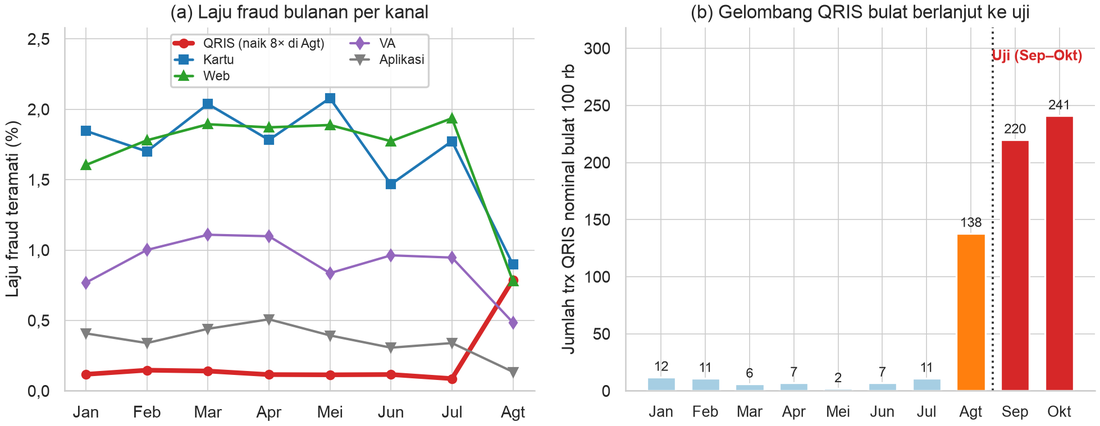

In [8]:
audit["pattern_shift"] = cek_pergeseran_pola_fraud(train, test, simpan_plot=True)
ringkas(audit["pattern_shift"])
tampilkan_gambar("task2_2a4_pattern_shift.png")

**2a.9 Pengukuran dampak** — `jalankan_semua_dampak()` menjalankan empat eksperimen pada split
kronologis yang labelnya matang, lalu seluruh hasil audit disimpan ke `task2_audit.json`.

pr_auc  roc_auc  ratio_pred_to_obs  flag_rate_pct  total_cost_idr
leakage_review_manual dengan_review_cv_naif            0.9017   0.9956             0.9615         0.8023      3.6775e+07
                      dengan_review_simulasi_uji       0.6889   0.9825             0.6850         0.6806      9.7322e+07
                      jujur_tanpa_review               0.7656   0.9873             0.9466         1.0953      7.4257e+07
label_delay_censoring val_jul_matang                   0.7830   0.9870             0.9977         1.2497      3.6901e+07
                      val_agt_penuh_tersensor          0.2747   0.9251             1.3453         1.2041      1.1865e+08
                      val_agt_akhir_15_31              0.1247   0.9254             2.2541         1.0910      3.8168e+07
                      val_agt_akhir_non_qris           0.1786   0.9852             3.7430         1.2207      8.3786e+06
seleksi_fitur_v       semua_50_v                       0.7566   0.9856             0.9185         1.0671      7.6476e+07
                      hanya_bernama_tanpa_v            0.7607   0.9862             0.9713         1.2414      7.7586e+07
                      bernama_plus_8_v_sinyal          0.7656   0.9873             0.9466         1.0953      7.4257e+07
indikator_kualitas    matang_jun_jul_dasar             0.7656   0.9873             0.9466         1.0953      7.4257e+07
                      matang_jun_jul_dengan_flag       0.7645   0.9877             0.9456         1.1323      7.4609e+07
                      qris_shift_agt11_21_dasar        0.5227   0.9865             0.7536         1.7300      8.7048e+06
                      qris_shift_agt11_21_dengan_flag  0.5733   0.9907             0.9438         1.8275      4.0054e+06

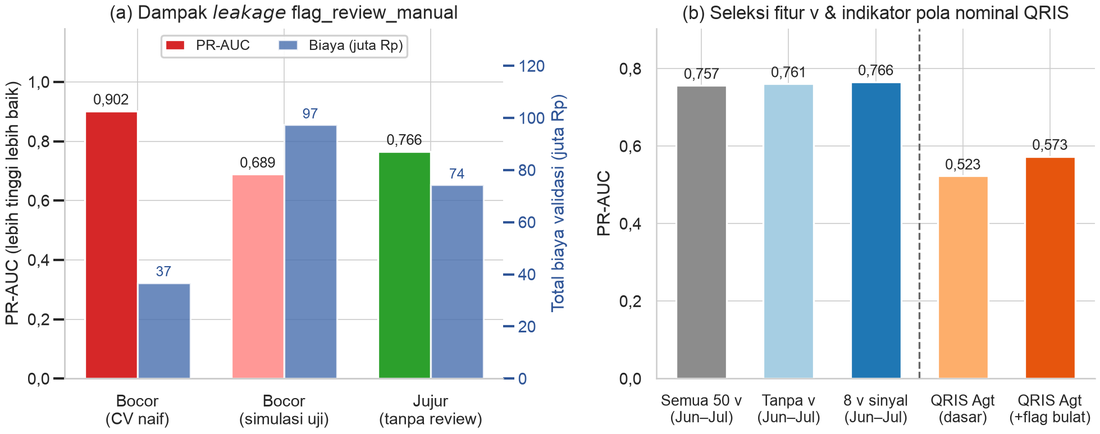

In [9]:
audit["dampak"] = jalankan_semua_dampak(train, seed=SEED, simpan_plot=True)
save_json(audit, RESULTS_DIR / "task2_audit.json")

kolom = ["pr_auc", "roc_auc", "ratio_pred_to_obs", "flag_rate_pct", "total_cost_idr"]
baris = {}
for eksperimen, isi in audit["dampak"].items():
    if not isinstance(isi, dict) or eksperimen == "split_info":
        continue
    for varian, metrik in isi.items():
        if isinstance(metrik, dict) and "pr_auc" in metrik:
            baris[(eksperimen, varian)] = {k: metrik.get(k) for k in kolom}
display(pd.DataFrame.from_dict(baris, orient="index"))
tampilkan_gambar("task2_2a5_dampak_audit.png")

## 2b. Validasi Berbasis Waktu yang Tahan *Right-Censoring*

*Penanggung jawab: Firdaus Arif Ramadhani*

Skema resmi: *expanding-window time CV* 3 *fold* (Mei, Juni, Juli 2025). Setiap *fold* validasi
berjarak ≥ 31 hari sebelum *snapshot* 31 Agustus 2025 sehingga labelnya matang. Skema ini
dibandingkan dengan:

- *stratified random* 5-*fold* CV pada Januari–Juli (optimisme semu karena waktu, pengguna, dan
  *merchant* yang sama tercampur);
- validasi naif pada Agustus yang labelnya belum lengkap.

In [10]:
from src.klasifikasi.validation import jalankan_validasi_klasifikasi

validasi = jalankan_validasi_klasifikasi(mode="all", simpan_json=True)

[START] Muat & siapkan data latih klasifikasi


[DONE]  Muat & siapkan data latih klasifikasi (1.18s)
[START] 2b.1 Expanding-Window Time CV Matang (3 Fold: Mei, Jun, Jul)


  Time CV Matang: PR-AUC=0.7767 ± 0.0274, Biaya/10k=7,208,807 Rp, rasio=0.92
[DONE]  2b.1 Expanding-Window Time CV Matang (3 Fold: Mei, Jun, Jul) (20.02s)
[START] 2b.2 Pembanding Stratified Random 5-Fold CV (Jan–Jul Matang)


  Random 5-Fold : PR-AUC=0.8132 ± 0.0191, Biaya/10k=7,633,963 Rp
[DONE]  2b.2 Pembanding Stratified Random 5-Fold CV (Jan–Jul Matang) (35.25s)
[START] 2b.3 Evaluasi Naif pada Agustus Tersensor (Agt 1–31 & 15–31)


  Agt 1–7 non-QRIS: PR-AUC=0.6805, rasio=1.12
  Agt 1–31 naif   : PR-AUC=0.2931, rasio=1.34
  Agt 15–31 berat : PR-AUC=0.1341, rasio=2.25
[DONE]  2b.3 Evaluasi Naif pada Agustus Tersensor (Agt 1–31 & 15–31) (8.27s)
[SAVED] task2_validation.json


**Time CV matang vs random CV**

,mean_pr_auc,std_pr_auc,mean_roc_auc,std_roc_auc,mean_cost_per_10k_tx_idr,mean_ratio_pred_to_obs
Time CV matang (3 fold),0.7767,0.0274,0.9863,0.0020,7.2088e+06,0.9191
Stratified random 5-fold,0.8132,0.0191,0.9880,0.0006,7.6340e+06,0.9271


**Evaluasi pada Agustus yang tersensor**

,n_val,n_val_fraud,obs_rate_pct,pr_auc,roc_auc,ratio_pred_to_obs
agt_1_7_matang,11785,110,0.9334,0.5074,0.9319,0.7981
agt_1_7_non_qris,9197,76,0.8264,0.6805,0.9894,1.1235
agt_penuh_1_31_naif,52904,245,0.4631,0.2931,0.9289,1.3360
agt_akhir_15_31_berat,28415,70,0.2463,0.1341,0.9303,2.2543


,nilai
optimisme_random_vs_time_pr_auc,0.0366
optimisme_random_vs_time_pct,4.7102
rasio_std_time_vs_random_pr_auc,1.4372
penurunan_pr_auc_naif_agt_vs_time,-0.4836
penurunan_pr_auc_agt15_31_vs_time,-0.6426
rasio_kalibrasi_agt15_31,2.2543


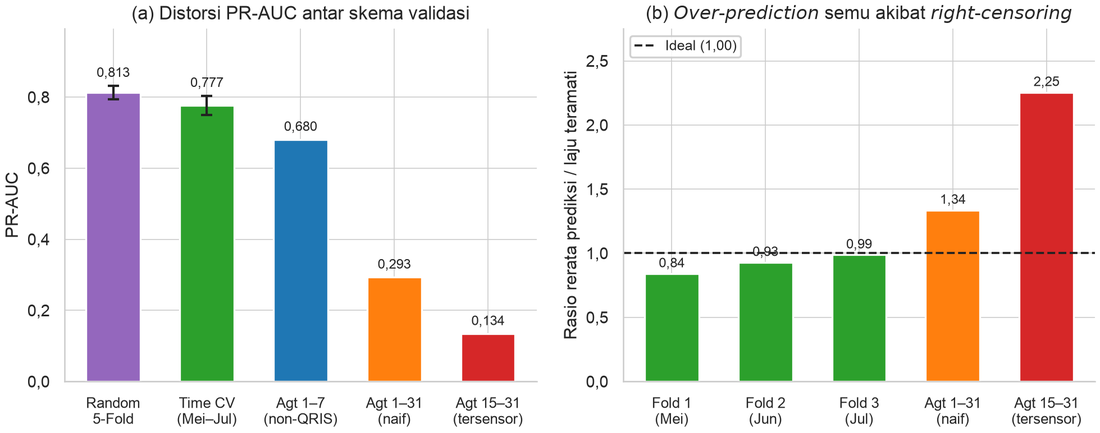

In [11]:
kolom = [
    "mean_pr_auc", "std_pr_auc", "mean_roc_auc", "std_roc_auc",
    "mean_cost_per_10k_tx_idr", "mean_ratio_pred_to_obs",
]
display(Markdown("**Time CV matang vs random CV**"))
display(tabel_metrik({
    "Time CV matang (3 fold)": validasi["time_cv_matang"],
    "Stratified random 5-fold": validasi["random_cv_matang"],
}, kolom))
display(Markdown("**Evaluasi pada Agustus yang tersensor**"))
display(tabel_metrik(validasi["validasi_agustus_tersensor"], [
    "n_val", "n_val_fraud", "obs_rate_pct", "pr_auc", "roc_auc", "ratio_pred_to_obs",
]))
display(pd.Series(validasi["ringkasan_selisih"], name="nilai", dtype=object).to_frame())
tampilkan_gambar("task2_2b_validation_comparison.png")

## 2c. Fitur Perilaku Kausal Pengguna dan *Merchant*

*Penanggung jawab: Rainaldi Pakpahan*

Semua fitur riwayat dihitung dari aliran transaksi yang diurutkan menurut waktu, dengan jaminan
hanya memakai transaksi sebelumnya (`t_past < t_now`):

- **Fitur perilaku tanpa label:** frekuensi, nominal, dan kebaruan transaksi per pengguna dan per
  *merchant* (pencarian biner tervektorisasi dengan `np.searchsorted`).
- **Fitur risiko historis berbasis label:** hanya memakai label yang sudah berumur ≥ 25 hari, agar
  konsisten dengan jeda konfirmasi pada validasi maupun data uji.

Ablasi bertahap menentukan himpunan fitur akhir.

In [12]:
from src.klasifikasi.features import jalankan_ablasi_fitur

fitur = jalankan_ablasi_fitur(save_json_flag=True)

[START] Muat data & verifikasi kausalitas ketat (Tugas 2c)


  Verifikasi kausalitas LULUS: mutasi masa depan mengubah fitur masa lalu sebesar 0,0.


[DONE]  Muat data & verifikasi kausalitas ketat (Tugas 2c) (3.99s)
[START] 2c Ablasi: dasar (43 fitur)


  PR-AUC matang=0.7767 ± 0.0274 | Biaya/10k=7,208,807 Rp | QRIS Agt=0.5751
[DONE]  2c Ablasi: dasar (43 fitur) (28.69s)
[START] 2c Ablasi: plus_domain (59 fitur)


  PR-AUC matang=0.7810 ± 0.0323 | Biaya/10k=7,203,261 Rp | QRIS Agt=0.5921
[DONE]  2c Ablasi: plus_domain (59 fitur) (31.71s)
[START] 2c Ablasi: plus_user (72 fitur)


  PR-AUC matang=0.7845 ± 0.0278 | Biaya/10k=7,433,116 Rp | QRIS Agt=0.6129
[DONE]  2c Ablasi: plus_user (72 fitur) (30.39s)
[START] 2c Ablasi: plus_merchant (90 fitur)


  PR-AUC matang=0.8056 ± 0.0289 | Biaya/10k=6,101,238 Rp | QRIS Agt=0.6160
[DONE]  2c Ablasi: plus_merchant (90 fitur) (35.12s)
[START] 2c Ablasi: lengkap_2c (94 fitur)


  PR-AUC matang=0.8069 ± 0.0284 | Biaya/10k=6,189,499 Rp | QRIS Agt=0.5661
[DONE]  2c Ablasi: lengkap_2c (94 fitur) (38.85s)


[SAVED] task2_features.json


**Ablasi bertahap kelompok fitur (Time CV matang)**

,n_features,mean_pr_auc,std_pr_auc,mean_roc_auc,mean_cost_per_10k_idr,qris_shift_pr_auc
tahap,,,,,,
dasar,43,0.7767,0.0274,0.9863,7.2088e+06,0.5751
plus_domain,59,0.7810,0.0323,0.9856,7.2033e+06,0.5921
plus_user,72,0.7845,0.0278,0.9862,7.4331e+06,0.6129
plus_merchant,90,0.8056,0.0289,0.9905,6.1012e+06,0.6160
lengkap_2c,94,0.8069,0.0284,0.9911,6.1895e+06,0.5661


Tahap terpilih: plus_merchant (90 fitur)
Alasan: Himpunan 90 fitur kausal bebas-label (plus_merchant) memberi biaya terendah dan PR-AUC tertinggi pada gelombang QRIS baru, sekaligus kebal terhadap jeda konfirmasi label pada merchant baru di data uji Sep–Okt.


**15 fitur perilaku dengan *gain* terbesar**

,fitur,gain_ribu
0,ato_risk_sum,35.0577
1,user_burst_1j_vs_7h,23.8500
2,collusive_risk_score,13.8082
3,refund_x_umur_merchant_inv,11.5624
4,merch_tx_30d,8.8079
5,merch_tx_7d,8.0627
6,merch_past_tx_count,3.7690
7,qris_x_log_nominal,2.2354
8,merch_nominal_vs_merch_mean,2.1986
9,log_menit_sejak_trx,2.1100


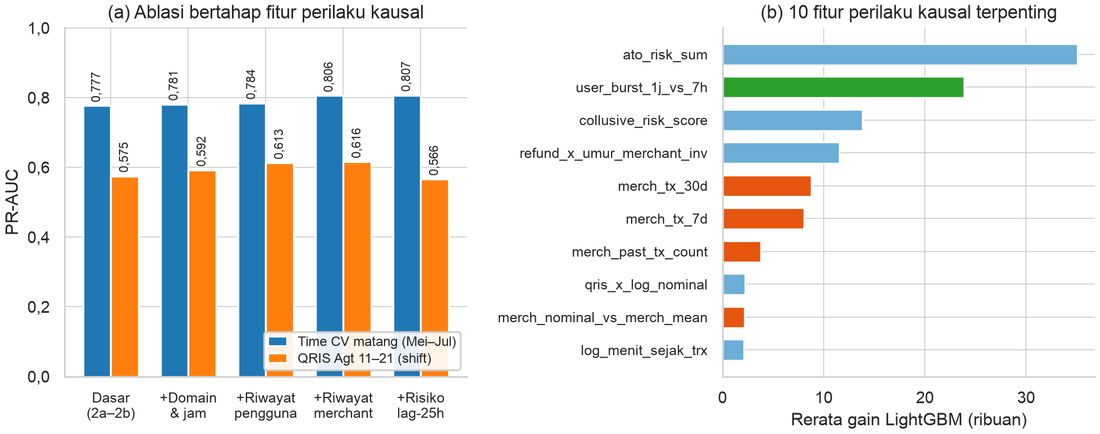

In [13]:
display(Markdown("**Ablasi bertahap kelompok fitur (Time CV matang)**"))
display(pd.DataFrame(fitur["ablasi"]).set_index("tahap"))
print(f"Tahap terpilih: {fitur['tahap_terpilih']} ({fitur['jumlah_fitur_terpilih']} fitur)")
print("Alasan:", fitur["alasan_pemilihan"])
display(Markdown("**15 fitur perilaku dengan *gain* terbesar**"))
display(pd.DataFrame(fitur["top_fitur_perilaku"]))
tampilkan_gambar("task2_2c_behavioral_features.png")

## 2d. Penanganan *Class Imbalance* dan Perbandingan Model

*Penanggung jawab: Rainaldi Pakpahan*

Semua eksperimen berjalan di dalam Time CV matang 2b dengan fitur 2c.

1. **Pendekatan *imbalance*** (pada LightGBM yang identik): prior alami, *class weighting*,
   *random undersampling* 1:10, SMOTE 1:10, *threshold tuning* F1, dan aturan Bayes berbasis biaya
   (`prob × nominal > 25.000`).
2. **Keluarga model:** *logistic regression* (*baseline*), LightGBM, CatBoost, XGBoost, dan *ensemble*
   *log-odds* berbobot.

In [9]:
%run ../src/klasifikasi/models.py

[START] Muat data & bangun fitur kausal 2c


[DONE]  Muat data & bangun fitur kausal 2c (3.86s)
[START] 2d.1 Perbandingan pendekatan class imbalance


  natural_ambang_05         : PR-AUC=0.8036, F1=0.7811, Brier=0.00213, Biaya/10k=13,643,913
  class_weighting_05        : PR-AUC=0.7952, F1=0.6358, Brier=0.00449, Biaya/10k=8,831,476
  class_weighting_bayes_raw : PR-AUC=0.7952, F1=0.2967, Brier=0.00449, Biaya/10k=8,691,412
  random_undersampling_1_10 : PR-AUC=0.7820, F1=0.6364, Brier=0.00489, Biaya/10k=7,772,656
  smote_oversampling_1_10   : PR-AUC=0.7972, F1=0.7871, Brier=0.00213, Biaya/10k=12,339,213
  threshold_tuning_f1       : PR-AUC=0.8036, F1=0.7951, Brier=0.00213, Biaya/10k=10,603,342
  cost_sensitive_bayes      : PR-AUC=0.8036, F1=0.5619, Brier=0.00213, Biaya/10k=6,355,882
[DONE]  2d.1 Perbandingan pendekatan class imbalance (95.06s)
[START] 2d.2 Baseline Logistic Regression (tuning C)


  LogReg (C=0.05): PR-AUC=0.6855, Biaya/10k=9,463,160
[DONE]  2d.2 Baseline Logistic Regression (tuning C) (30.47s)
[START] 2d.3 LightGBM (tuning dalam 3-Fold Time CV)


  LightGBM terbaik: PR-AUC=0.8080, Biaya/10k=5,864,297
[DONE]  2d.3 LightGBM (tuning dalam 3-Fold Time CV) (106.32s)
[START] 2d.4 CatBoost (tuning dalam 3-Fold Time CV)


  CatBoost terbaik: PR-AUC=0.8009, Biaya/10k=6,451,529
[DONE]  2d.4 CatBoost (tuning dalam 3-Fold Time CV) (353.65s)
[START] 2d.5 XGBoost (tuning dalam 3-Fold Time CV)


  XGBoost terbaik : PR-AUC=0.8029, Biaya/10k=6,337,493
[DONE]  2d.5 XGBoost (tuning dalam 3-Fold Time CV) (47.12s)


  Ensemble Blend  : PR-AUC=0.8134 (F3 OOS=0.8152), Biaya/10k=6,039,213 | bobot={'lgbm': 0.6464911682487486, 'catboost': 0.23865225986528354, 'xgboost': 0.11485657188596787}


[SAVED] task2_models.json & cache/task2_oof.npz


**Perbandingan pendekatan class imbalance**

,mean_pr_auc,std_pr_auc,mean_roc_auc,mean_recall,mean_flag_rate_pct,total_cost_3fold_idr
cost_sensitive_bayes,0.8036,0.0292,0.9905,0.6870,0.9365,9.8604e+07
random_undersampling_1_10,0.7820,0.0229,0.9896,0.8054,0.9931,1.2078e+08
class_weighting_bayes_raw,0.7952,0.0262,0.9903,0.7866,2.7984,1.3482e+08
class_weighting_05,0.7952,0.0262,0.9903,0.8044,0.9916,1.3672e+08
threshold_tuning_f1,0.8036,0.0292,0.9905,0.7284,0.5394,1.6441e+08
smote_oversampling_1_10,0.7972,0.0302,0.9884,0.6790,0.4703,1.9151e+08
natural_ambang_05,0.8036,0.0292,0.9905,0.6705,0.4639,2.1140e+08


**Perbandingan keluarga model**

,mean_pr_auc,std_pr_auc,mean_roc_auc,mean_recall,mean_flag_rate_pct,total_cost_3fold_idr
lgbm,0.8080,0.0259,0.9909,0.7023,1.0484,9.1017e+07
ensemble,0.8134,0.0239,0.9907,0.7010,1.0037,9.3690e+07
xgboost,0.8029,0.0230,0.9905,0.6961,1.1717,9.8309e+07
catboost,0.8009,0.0222,0.9881,0.6900,0.9698,1.0007e+08
logreg,0.6855,0.0225,0.9748,0.6147,1.2711,1.4703e+08


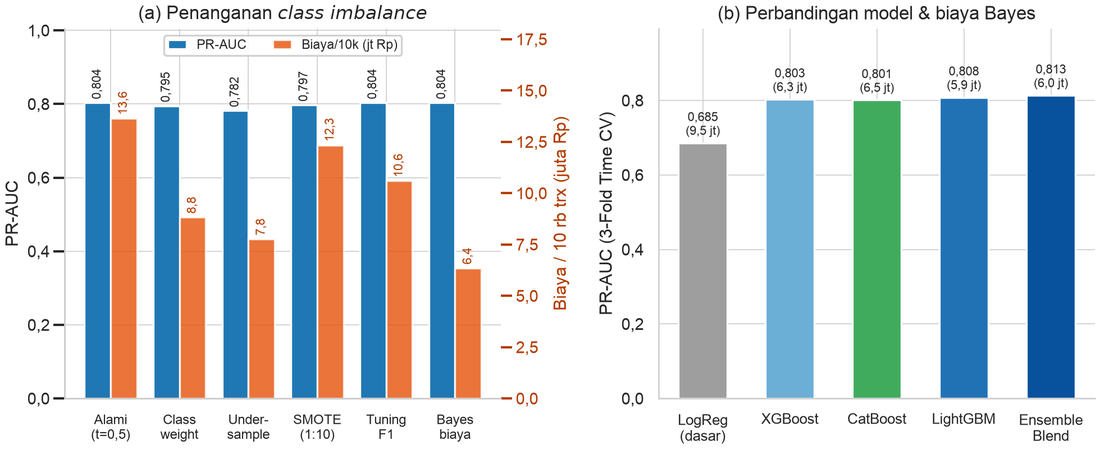

In [10]:
model = baca_hasil("task2_models.json")
kolom = [
    "mean_pr_auc", "std_pr_auc", "mean_roc_auc", "mean_recall",
    "mean_flag_rate_pct", "total_cost_3fold_idr",
]
display(Markdown("**Perbandingan pendekatan class imbalance**"))
display(tabel_metrik(model["imbalance_comparison"], kolom).sort_values("total_cost_3fold_idr"))
display(Markdown("**Perbandingan keluarga model**"))
display(tabel_metrik(model["model_comparison"], kolom).sort_values("total_cost_3fold_idr"))
tampilkan_gambar("task2_2d_imbalance_and_models.png")

## 2e. Pergeseran Pola *Fraud* dan Adaptasi Model

*Penanggung jawab: Rainaldi Pakpahan*

Gelombang *fraud* QRIS bernominal bulat muncul mulai 1 Agustus 2025. Enam strategi adaptasi
dibandingkan secara kronologis: latih sampai 10 Agustus, evaluasi pada 11–21 Agustus (ekor 22–31
Agustus yang labelnya paling tersensor dibuang). Strategi mencakup tanpa adaptasi, menambah data awal
Agustus dengan bobot 1×, 3×, 6×, 10×, serta peluruhan waktu.

In [11]:
%run ../src/klasifikasi/shift.py

[START] Muat data & fitur kausal 2c untuk eksperimen shift 2e


[DONE]  Muat data & fitur kausal 2c untuk eksperimen shift 2e (3.44s)


[START] 2e Evaluasi strategi: tanpa_adaptasi_jan_jul


  Overall PR-AUC=0.2525 | QRIS PR-AUC=0.1749 (rec=22.5%) | Non-QRIS PR-AUC=0.3809 | Cost=43.03M Rp
[DONE]  2e Evaluasi strategi: tanpa_adaptasi_jan_jul (11.64s)
[START] 2e Evaluasi strategi: tambah_agt_awal_1x


  Overall PR-AUC=0.4292 | QRIS PR-AUC=0.5989 (rec=87.5%) | Non-QRIS PR-AUC=0.4009 | Cost=9.74M Rp
[DONE]  2e Evaluasi strategi: tambah_agt_awal_1x (11.74s)
[START] 2e Evaluasi strategi: recency_3x


  Overall PR-AUC=0.4690 | QRIS PR-AUC=0.6355 (rec=90.0%) | Non-QRIS PR-AUC=0.4152 | Cost=9.00M Rp
[DONE]  2e Evaluasi strategi: recency_3x (11.57s)
[START] 2e Evaluasi strategi: recency_6x


  Overall PR-AUC=0.4672 | QRIS PR-AUC=0.5981 (rec=87.5%) | Non-QRIS PR-AUC=0.4172 | Cost=9.39M Rp
[DONE]  2e Evaluasi strategi: recency_6x (11.34s)
[START] 2e Evaluasi strategi: recency_10x


  Overall PR-AUC=0.4560 | QRIS PR-AUC=0.5998 (rec=87.5%) | Non-QRIS PR-AUC=0.3950 | Cost=10.55M Rp
[DONE]  2e Evaluasi strategi: recency_10x (11.77s)
[START] 2e Evaluasi strategi: decay_dan_recency_6x


  Overall PR-AUC=0.4670 | QRIS PR-AUC=0.6119 (rec=87.5%) | Non-QRIS PR-AUC=0.4059 | Cost=10.10M Rp
[DONE]  2e Evaluasi strategi: decay_dan_recency_6x (11.65s)


[SAVED] task2_shift.json


,w_recent,decay_half_life_days,overall_pr_auc,qris_pr_auc,qris_recall,non_qris_pr_auc,overall_cost_idr
strategi,,,,,,,
tanpa_adaptasi_jan_jul,0.0,NaN,0.2525,0.1749,0.225,0.3809,4.3031e+07
tambah_agt_awal_1x,1.0,NaN,0.4292,0.5989,0.875,0.4009,9.7367e+06
recency_3x,3.0,NaN,0.4690,0.6355,0.900,0.4152,8.9957e+06
recency_6x,6.0,NaN,0.4672,0.5981,0.875,0.4172,9.3867e+06
recency_10x,10.0,NaN,0.4560,0.5998,0.875,0.3950,1.0546e+07
decay_dan_recency_6x,6.0,180.0,0.4670,0.6119,0.875,0.4059,1.0103e+07


,strategi terpilih
decay_half_life_days,None
nama,recency_3x
overall_cost_idr,8995700.0
overall_pr_auc,0.469
penghematan_vs_tanpa_adaptasi_idr,34035200.0
qris_pr_auc,0.6355
qris_recall,0.9
w_recent,3.0


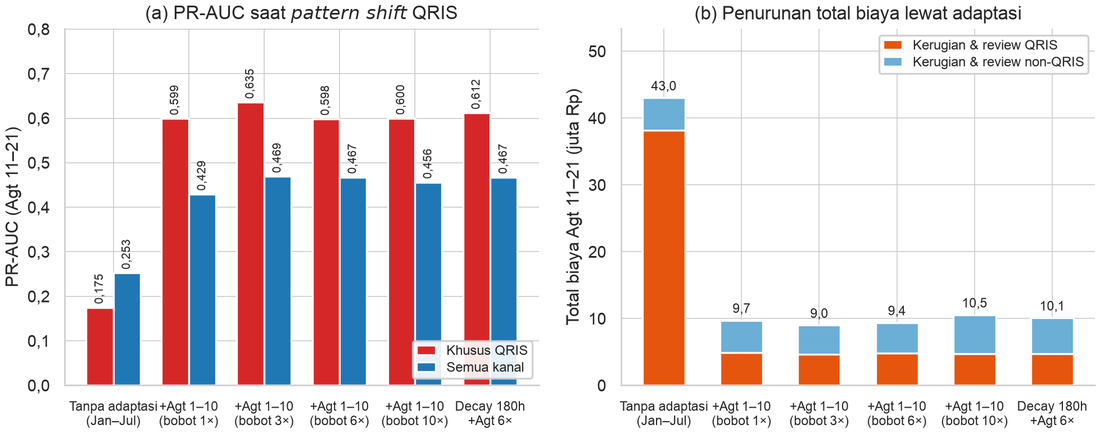

In [12]:
shift = baca_hasil("task2_shift.json")
kolom = [
    "w_recent", "decay_half_life_days", "overall_pr_auc", "qris_pr_auc",
    "qris_recall", "non_qris_pr_auc", "overall_cost_idr",
]
display(pd.DataFrame(shift["strategi"]).set_index("strategi")[kolom])
display(pd.Series(shift["strategi_terpilih"], name="strategi terpilih", dtype=object).to_frame())
tampilkan_gambar("task2_2e_pattern_shift_adaptation.png")

## 2f. Kalibrasi Probabilitas dan Aturan Keputusan Berbasis Biaya

*Penanggung jawab: Rainaldi Pakpahan*

Kalibrator dipasang pada OOF *fold* 1–2 (Mei–Juni) dan dievaluasi pada *fold* 3 (Juli):
tanpa kalibrasi, *Platt scaling*, *isotonic*, dan *beta calibration*. Dengan probabilitas yang
terkalibrasi, aturan keputusan Bayes `tandai = 1 jika prob × nominal > 25.000` dibandingkan dengan
menandai semua, tidak menandai apa pun, ambang tetap, dan batas bawah *oracle*.

In [13]:
%run ../src/klasifikasi/calibration.py

[START] 2f.1 Kalibrasi kronologis (Fit Mei–Jun -> Eval Jul)


  uncalibrated      : PR-AUC=0.8152 | Brier=0.00210 | LogLoss=0.00938 | ECE=0.00052 | Biaya F3=32.07M Rp
  platt_scaling     : PR-AUC=0.8152 | Brier=0.00206 | LogLoss=0.00946 | ECE=0.00031 | Biaya F3=33.71M Rp
  beta_calibration  : PR-AUC=0.8152 | Brier=0.00206 | LogLoss=0.00923 | ECE=0.00036 | Biaya F3=33.18M Rp
  isotonic          : PR-AUC=0.7986 | Brier=0.00208 | LogLoss=0.00928 | ECE=0.00037 | Biaya F3=33.55M Rp
  Kalibrator terpilih: beta_calibration
[DONE]  2f.1 Kalibrasi kronologis (Fit Mei–Jun -> Eval Jul) (0.18s)
[START] 2f.2 Evaluasi aturan keputusan berbasis biaya vs baseline


  tandai_semua              : Biaya=1308.35M Rp (lolos=  0.00M, review=1308.35M, flag=100.00%, rec=100.0%)
  tandai_nol                : Biaya= 347.60M Rp (lolos=347.60M, review=  0.00M, flag= 0.00%, rec=  0.0%)
  ambang_tetap_05           : Biaya=  43.50M Rp (lolos= 36.30M, review=  7.20M, flag= 0.55%, rec= 73.9%)
  ambang_tetap_f1           : Biaya=  41.24M Rp (lolos= 33.39M, review=  7.85M, flag= 0.60%, rec= 76.2%)
  aturan_bayes_uncal        : Biaya=  32.07M Rp (lolos= 18.72M, review= 13.35M, flag= 1.02%, rec= 71.0%)
  aturan_bayes_terkalibrasi : Biaya=  33.18M Rp (lolos= 17.51M, review= 15.68M, flag= 1.20%, rec= 72.4%)
  aturan_bayes_tuned_k      : Biaya=  33.12M Rp (lolos= 18.27M, review= 14.85M, flag= 1.14%, rec= 71.0%)
  oracle_teoritis           : Biaya=   8.02M Rp (lolos=  0.55M, review=  7.47M, flag= 0.57%, rec= 87.7%)
[DONE]  2f.2 Evaluasi aturan keputusan berbasis biaya vs baseline (0.59s)


[SAVED] task2_calibration.json & cache/task2_fold3_calibrated.npz


**Perbandingan kalibrator (fold 3, Juli)**

,pr_auc,brier,log_loss,ece_15bin,ratio_pred_to_obs,total_cost_idr
beta_calibration,0.8152,0.0021,0.0092,0.0004,1.0484,3.3181e+07
isotonic,0.7986,0.0021,0.0093,0.0004,1.0507,3.3548e+07
platt_scaling,0.8152,0.0021,0.0095,0.0003,1.0434,3.3713e+07
uncalibrated,0.8152,0.0021,0.0094,0.0005,0.9548,3.2073e+07


Kalibrator terpilih: beta_calibration


**Perbandingan aturan keputusan**

,n_flagged,precision,recall,review_cost_idr,missed_fraud_loss_idr,total_cost_idr
oracle_teoritis,299,1.0000,0.8768,7.4750e+06,5.4700e+05,8.0220e+06
aturan_bayes_uncal,534,0.4532,0.7097,1.3350e+07,1.8723e+07,3.2073e+07
aturan_bayes_tuned_k,594,0.4074,0.7097,1.4850e+07,1.8272e+07,3.3122e+07
aturan_bayes_terkalibrasi,627,0.3939,0.7243,1.5675e+07,1.7506e+07,3.3181e+07
ambang_tetap_f1,314,0.8280,0.7625,7.8500e+06,3.3387e+07,4.1237e+07
ambang_tetap_05,288,0.8750,0.7390,7.2000e+06,3.6297e+07,4.3497e+07
tandai_nol,0,0.0000,0.0000,0.0000e+00,3.4760e+08,3.4760e+08
tandai_semua,52334,0.0065,1.0000,1.3084e+09,0.0000e+00,1.3084e+09


,nilai
hemat_vs_tandai_nol_idr,314422400.0
hemat_vs_tandai_nol_pct,90.4545
hemat_vs_tandai_semua_idr,1275169400.0
hemat_vs_tandai_semua_pct,97.4639


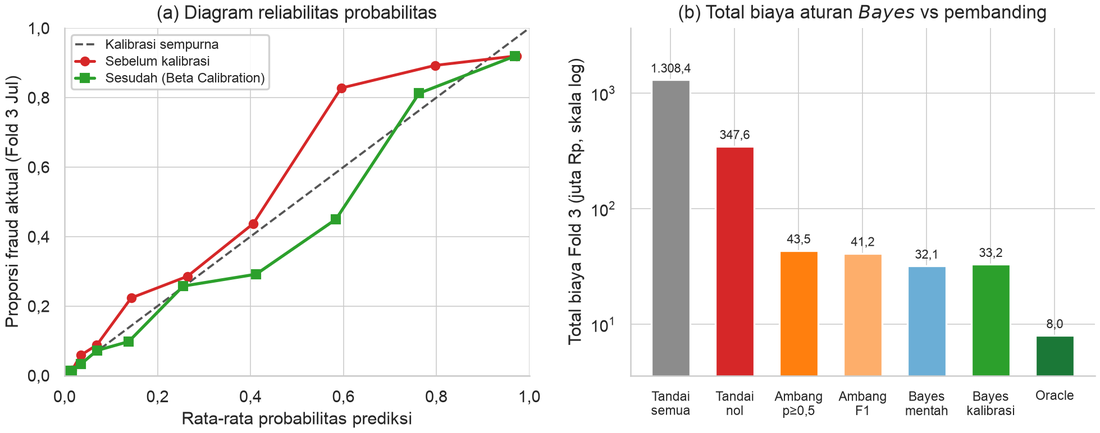

In [14]:
kalibrasi = baca_hasil("task2_calibration.json")
display(Markdown("**Perbandingan kalibrator (fold 3, Juli)**"))
display(tabel_metrik(kalibrasi["perbandingan_kalibrasi"], [
    "pr_auc", "brier", "log_loss", "ece_15bin", "ratio_pred_to_obs", "total_cost_idr",
]))
print("Kalibrator terpilih:", kalibrasi["kalibrator_terpilih"])
display(Markdown("**Perbandingan aturan keputusan**"))
display(tabel_metrik(kalibrasi["perbandingan_aturan_keputusan"], [
    "n_flagged", "precision", "recall", "review_cost_idr", "missed_fraud_loss_idr", "total_cost_idr",
]).sort_values("total_cost_idr"))
display(pd.Series(kalibrasi["ringkasan_penghematan_f3"], name="nilai", dtype=object).to_frame())
tampilkan_gambar("task2_2f_calibration_and_cost.png")

## 2g. Analisis *Error*, SHAP, dan Prediksi Akhir

*Penanggung jawab: Rainaldi Pakpahan*

1. Pemecahan *error* model terkalibrasi (*fold* 3) per kanal, kategori *merchant*, dan arketipe pola
   *fraud*, ditambah evaluasi gelombang QRIS pada 11–21 Agustus.
2. Kontribusi fitur global dengan `shap.TreeExplainer` pada LightGBM.
3. Pelatihan ulang *ensemble* produksi pada Januari–Agustus dengan pembobotan adaptif 2e dan
   koreksi *right-censoring*, lalu kalibrasi 2f.
4. Penulisan dan validasi `prediksi_klasifikasi.csv`.

In [15]:
%run ../src/klasifikasi/analysis.py

[START] Muat data & bangun fitur kausal bebas-label (Train + Test)


[DONE]  Muat data & bangun fitur kausal bebas-label (Train + Test) (4.34s)
[START] 2g.1 Pemecahan error per kanal, kategori merchant, & 5 arketipe pola fraud


  Error Fold 3 per kanal:
    aplikasi  : fraud= 79, rec= 64.6%, cost= 9.37M (missed= 4.49M)
    kartu     : fraud=116, rec= 69.0%, cost= 8.10M (missed= 4.20M)
    qris      : fraud= 10, rec= 30.0%, cost= 7.44M (missed= 5.74M)
    va        : fraud= 74, rec= 87.8%, cost= 5.10M (missed= 1.80M)
    web       : fraud= 62, rec= 77.4%, cost= 3.18M (missed= 1.28M)
  Gelombang QRIS (Agt 11–21 adaptif): fraud=40, rec=90.0%, PR-AUC=0.6355
[DONE]  2g.1 Pemecahan error per kanal, kategori merchant, & 5 arketipe pola fraud (12.35s)
[START] 2g.2 Refit production ensemble (LGBM + CatBoost + XGBoost) adaptif shift & sensor


[DONE]  2g.2 Refit production ensemble (LGBM + CatBoost + XGBoost) adaptif shift & sensor (106.81s)
[START] 2g.3 Hitung SHAP TreeExplainer (sampel 4.000 baris uji + fraud Fold 3)


  Top 5 SHAP: kategori_merchant=0.582, merch_tx_30d=0.389, merch_days_since_first_tx=0.307, jumlah_akun_per_perangkat=0.196, merch_tx_7d=0.176
[DONE]  2g.3 Hitung SHAP TreeExplainer (sampel 4.000 baris uji + fraud Fold 3) (1.46s)
[START] 2g.4 Tulis & validasi prediksi_klasifikasi.csv
  VALIDASI LULUS | n=106,674, mean_prob=0.805%, flagged=1,446 (1.36%)
  Sanity QRIS bulat 100rb (n=461): mean_prob=70.0%, flagged=93.7% | QRIS normal mean_prob=0.201%
[DONE]  2g.4 Tulis & validasi prediksi_klasifikasi.csv (0.15s)
[SAVED] task2_analysis.json & prediksi_klasifikasi.csv


**Error fold 3 per kanal**

,n_trx,n_fraud,tp,fp,fn,precision,recall,pr_auc,total_cost_idr
grup,,,,,,,,,
aplikasi,23266,79,51,144,28,0.2615,0.6456,0.7340,9365100.0
kartu,6541,116,80,76,36,0.5128,0.6897,0.8665,8098800.0
qris,11508,10,3,65,7,0.0441,0.3000,0.1861,7436200.0
va,7817,74,65,67,9,0.4924,0.8784,0.8023,5096900.0
web,3202,62,48,28,14,0.6316,0.7742,0.9249,3183600.0


**Error fold 3 per arketipe fraud**

,n_trx,n_fraud,tp,fp,fn,precision,recall,pr_auc,total_cost_idr
grup,,,,,,,,,
Anomali Merchant & Lainnya,32491,62,35,181,27,0.1620,0.5645,0.4506,1.4474e+07
Gelombang QRIS,11508,10,3,65,7,0.0441,0.3000,0.1861,7.4362e+06
Pengambilalihan Akun (ATO),4059,144,133,75,11,0.6394,0.9236,0.9304,6.9540e+06
Merchant Kolusif (Nominal Besar),390,45,45,54,0,0.4545,1.0000,0.7858,2.4750e+06
Card Testing & Velocity,3886,80,31,5,49,0.8611,0.3875,0.9228,1.8412e+06


**Gelombang QRIS pada jendela 11–21 Agustus**

,nilai
flag_rate_pct,1.7788
fn,4
fp,37
grup,Gelombang QRIS
missed_loss_idr,2869700.0
n_fraud,40
n_trx,4104
pr_auc,0.6355
precision,0.4932
recall,0.9


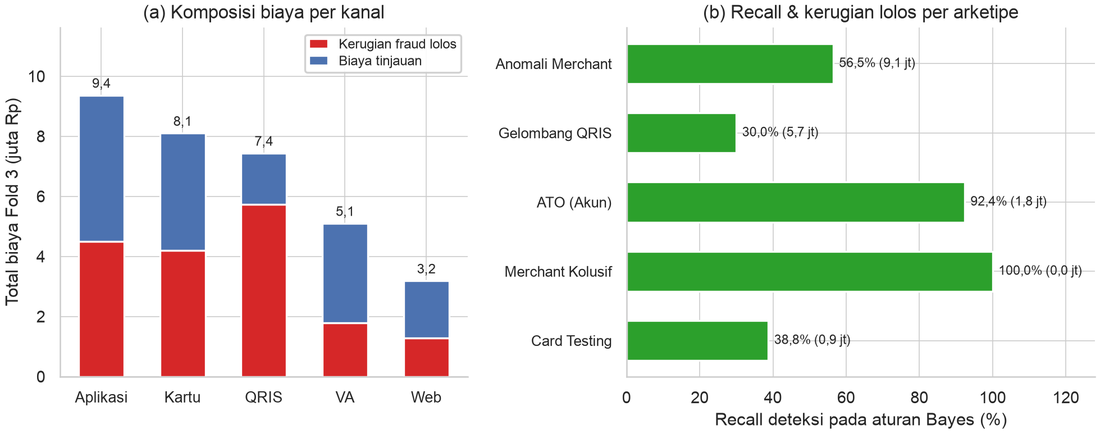

**20 fitur dengan rata-rata |SHAP| terbesar**

,fitur,mean_abs_shap
0,kategori_merchant,0.5817
1,merch_tx_30d,0.3893
2,merch_days_since_first_tx,0.3070
3,jumlah_akun_per_perangkat,0.1958
4,merch_tx_7d,0.1762
5,merch_past_tx_count,0.1706
6,nominal,0.1374
7,user_past_tx_count,0.1369
8,ato_risk_sum,0.1334
9,persen_saldo,0.1232


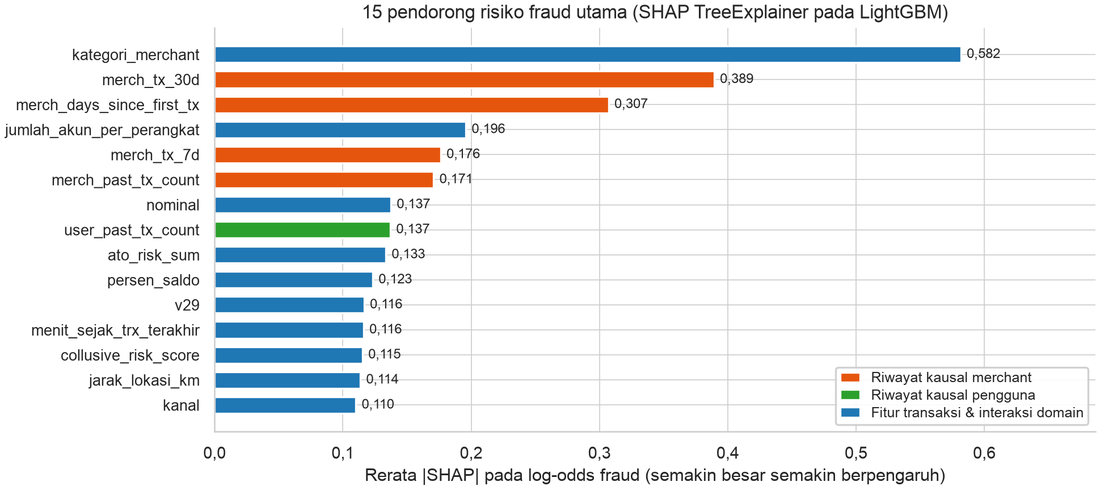

**Konfigurasi model produksi**

,nilai
decay_half_life_days,None
ensemble_weights,"{'catboost': 0.23865225986528354, 'lgbm': 0.64..."
kalibrator,beta_calibration
n_train_rows,386364
w_recent,3.0


In [16]:
analisis = baca_hasil("task2_analysis.json")
kolom = ["n_trx", "n_fraud", "tp", "fp", "fn", "precision", "recall", "pr_auc", "total_cost_idr"]
for kunci, judul in (("error_fold3_per_kanal", "kanal"), ("error_fold3_per_arketipe", "arketipe fraud")):
    display(Markdown(f"**Error fold 3 per {judul}**"))
    display(pd.DataFrame(analisis[kunci]).set_index("grup")[kolom])
display(Markdown("**Gelombang QRIS pada jendela 11–21 Agustus**"))
display(pd.Series(analisis["error_shift_agt11_21_qris"], name="nilai", dtype=object).to_frame())
tampilkan_gambar("task2_2g_error_breakdown.png")

display(Markdown("**20 fitur dengan rata-rata |SHAP| terbesar**"))
display(pd.DataFrame(analisis["shap_top20"]))
tampilkan_gambar("task2_2g_shap_summary.png")
display(Markdown("**Konfigurasi model produksi**"))
display(pd.Series(analisis["produksi_info"], name="nilai", dtype=object).to_frame())

Pemeriksaan akhir berkas `prediksi_klasifikasi.csv` di *root* repositori: kolom, urutan ID sama
dengan data uji, `prob` di rentang [0, 1], dan `tandai` bernilai 0 atau 1.

In [17]:
from src.config import KLASIFIKASI_TEST_PATH, PRED_KLASIFIKASI_PATH

prediksi = pd.read_csv(PRED_KLASIFIKASI_PATH)
uji = pd.read_csv(KLASIFIKASI_TEST_PATH, usecols=["id_transaksi"])
assert list(prediksi.columns) == ["id_transaksi", "prob", "tandai"]
assert len(prediksi) == len(uji) and prediksi["id_transaksi"].equals(uji["id_transaksi"])
assert prediksi["prob"].between(0, 1).all()
assert set(prediksi["tandai"].unique()) <= {0, 1}
print(f"{PRED_KLASIFIKASI_PATH.name}: {len(prediksi):,} baris, kontrak terpenuhi")
print(f"Transaksi ditandai: {prediksi['tandai'].sum():,} ({prediksi['tandai'].mean():.2%})")
display(prediksi.head())

prediksi_klasifikasi.csv: 106,674 baris, kontrak terpenuhi
Transaksi ditandai: 1,446 (1.36%)


,id_transaksi,prob,tandai
0,T502861791,4.8550e-03,0
1,T980390558,3.4000e-05,0
2,T657838379,1.4000e-05,0
3,T985886276,1.6600e-04,0
4,T852019235,5.3300e-04,0
